In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from fvcore.nn import FlopCountAnalysis
import torch

sys.path.append(str(Path().resolve().parent / "src"))

plt.style.use("ggplot")

from models import build_model
from config import read_model_config
from data import StructureSelector


# Parameters

In [4]:
PRED_GROUPS = ['ct', 'body', 'ptv_doses', 'oar_v3_sdm']
PLAN_GROUPS = ['ct', 'body', 'ptv_doses', 'oar_v3_sdm', 'beam_plate', 'angle_plate']

In [ ]:
config = read_model_config('200-mamba')
model = build_model(config, StructureSelector(PLAN_GROUPS))
print(sum(p.numel() for p in model.parameters() if p.requires_grad))

In [4]:
pred_sizes = pd.Series({
	'00-mamba':          29287392,
	'01-beamdiff':       80201345,
	'02-spdiffdose':     88770801,
	'03-dosediff':       23240001,
	'04-diffdp':        439128385,
	'05-c3d-2d':         14725282,
	'06-mednext-m':      17419202,
	'07-deeplabv3plus':  27913505,
	'08-ddpm-mednext-m': 30064577,
	'09-hdunet':          1427815,
	'10-mednext-v2-m':   17474946,
})

pred_sizes

00-mamba              29287392
01-beamdiff           80201345
02-spdiffdose         88770801
03-dosediff           23240001
04-diffdp            439128385
05-c3d-2d             14725282
06-mednext-m          17419202
07-deeplabv3plus      27913505
08-ddpm-mednext-m     30064577
09-hdunet              1427815
10-mednext-v2-m       17474946
dtype: int64

In [ ]:
plan_sizes = pd.Series({
	'00-mamba':          29287824,
	'01-beamdiff':      127420545,
	'02-spdiffdose':     88771953,
	'03-dosediff':       28343745,
	'04-diffdp':        439129537,
	'05-c3d-2d':         14726146,
	'06-mednext-m':      17419266,
	'07-deeplabv3plus':  27919777,
	'08-ddpm-mednext-m': 30065153,
	'09-hdunet':          1429043,
	'10-mednext-v2-m':   17475010,
})

plan_sizes

00-mamba              29287824
01-beamdiff          127420545
02-spdiffdose         88771953
03-dosediff           28343745
04-diffdp            439129537
05-c3d-2d             14726146
06-mednext-m          17419266
07-deeplabv3plus      27919777
08-ddpm-mednext-m     30065153
09-hdunet              1429043
10-mednext-v2-m       17475010
dtype: int64

In [6]:
sizes = pd.DataFrame({
  'pred_size': pred_sizes,
  'plan_size': plan_sizes,
})
sizes = sizes.reset_index().rename(columns={'index': 'model'})

sizes

,model,pred_size,plan_size
0,00-mamba,29287392,29287824
1,01-beamdiff,80201345,127420545
2,02-spdiffdose,88770801,88771953
3,03-dosediff,23240001,28343745
4,04-diffdp,439128385,439129537
5,05-c3d-2d,14725282,14726146
6,06-mednext-m,17419202,17419266
7,07-deeplabv3plus,27913505,27919777
8,08-ddpm-mednext-m,30064577,30065153
9,09-hdunet,1427815,1429043


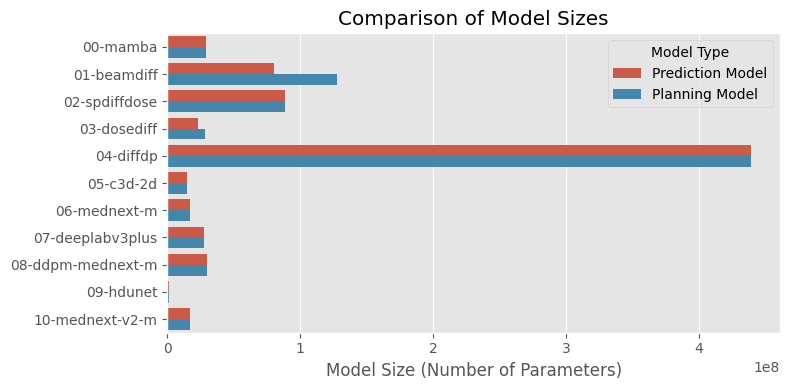

In [13]:
plot_data = sizes.melt(id_vars='model', value_vars=['pred_size', 'plan_size'], var_name='type', value_name='size')
plot_data['type'] = plot_data['type'].map({'pred_size': 'Prediction Model', 'plan_size': 'Planning Model'})

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(plot_data, x='size', y='model', hue='type', ax=ax)
ax.set_xlabel('Model Size (Number of Parameters)')
ax.set_ylabel('')
ax.set_title('Comparison of Model Sizes')
plt.legend(title='Model Type')
plt.tight_layout()

# FLOPs

In [16]:
config = read_model_config('106-mednext-m')
selector = StructureSelector(PRED_GROUPS)
model = build_model(config, selector).eval()

# Create dummy inputs
dummy_noisy = torch.randn(1, 1, 176, 160)
dummy_cond = torch.randn(1, selector.total_channels, 176, 160)
dummy_t = torch.tensor([1])

with torch.no_grad():
  flops = FlopCountAnalysis(model, (dummy_cond))

flops.total()

/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/.venv/lib/python3.13/site-packages/torch/_dynamo/eval_frame.py:929: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In version 2.5 we will raise an exception if use_reentrant is not passed. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


RuntimeError: unordered_map::at: key not found

In [ ]:
pred_sizes = pd.Series({
  '00-mamba':          ,
  '01-beamdiff':       110995125504,
  '02-spdiffdose':      69445664768,
  '03-dosediff':        45587529216,
  '04-diffdp':          63521647616,
  '05-c3d-2d':          10672527360,
  '06-mednext-m':      ,
  '07-deeplabv3plus':  ,
  '08-ddpm-mednext-m': ,
  '09-hdunet':          ,
  '10-mednext-v2-m':   ,
})

pred_sizes